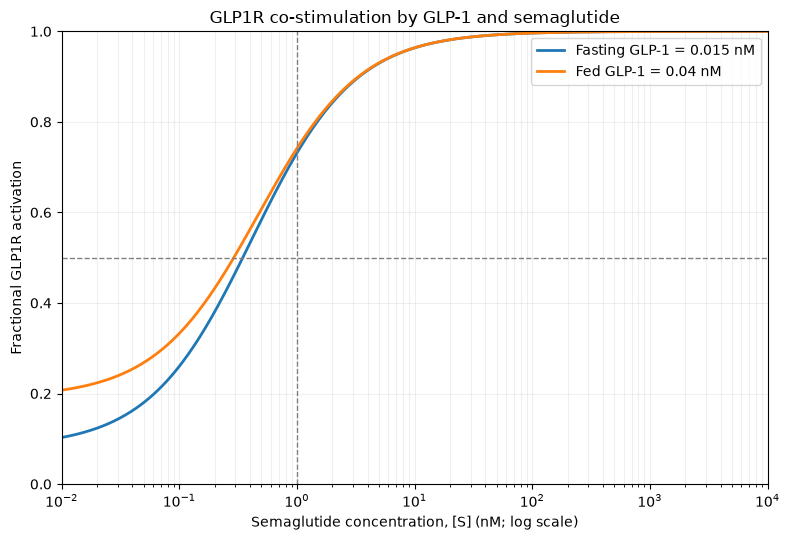

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# dissociation constants (nM).
# Kd1: GLP-1 binding Kd2: semaglutide binding.
Kd1 = 0.17
Kd2 = 0.38

# GLP-1 concentrations (nM).
GLP1_FASTING = 0.0150
GLP1_FED = 0.040

# semaglutide ligand concentration, 0.01 to 10,000 [nM]
S = np.logspace(-2, 4, 500)

def Fact(G, S, Kd1, Kd2):
    """Fractional GLP1R activation by co-stimulation with GLP-1 and semaglutide."""
    return (Kd2 * G + Kd1 * S) / (Kd1 * Kd2 + Kd2 * G + Kd1 * S)

# calculate fact at fasting & fed levels
response_fasting = Fact(GLP1_FASTING, S, Kd1, Kd2)
response_fed = Fact(GLP1_FED, S, Kd1, Kd2)

plt.figure(figsize=(8, 5.5))
plt.semilogx(S, response_fasting, linewidth=2,
             label=f"Fasting GLP-1 = {GLP1_FASTING:g} nM")
plt.semilogx(S, response_fed, linewidth=2,
             label=f"Fed GLP-1 = {GLP1_FED:g} nM")
plt.axhline(0.5, ls="--", c="gray", lw=1)
plt.axvline(1, ls="--", c="gray", lw=1)
plt.xlabel("Semaglutide concentration, [S] (nM; log scale)")
plt.ylabel("Fractional GLP1R activation")
plt.title("GLP1R co-stimulation by GLP-1 and semaglutide")
plt.ylim(0, 1)
plt.xlim(S.min(), S.max())
plt.grid(True, which="both", alpha=0.2)
plt.legend()
plt.tight_layout()
plt.savefig("GLP1_GLP1R.png", dpi=300)
plt.show()

There is greater amount of response at the fed GLP-1 level than the fasting GLP-1 level. The graph for the fed level (in orange) is above the fasting level (blue), showing that there is a greater fraction of active receptors. In large concentrations of semaglutide, both fasting and fed levels of GLP-1 trend towards 100% fraction of active receptors.